# BÀI KIỂM TRA 1: KHẢO SÁT, ĐÁNH GIÁ CHẤT LƯỢNG VÀ TIỀN XỬ LÝ DỮ LIỆU
**Học phần:** Học máy (Machine Learning)  
**Đề tài:** Dự báo điện năng tiêu thụ theo giờ của hộ gia đình (*Individual Household Electric Power Consumption*)

---

## 1. Phát biểu bài toán, Mục tiêu và Từ điển dữ liệu

### 1.1 Tóm tắt bài toán và Mục tiêu học máy
* **Loại bài toán:** Hồi quy chuỗi thời gian đơn biến/đa biến (*Time Series Regression*). Đầu ra là đại lượng thực liên tục (điện năng theo giờ, đơn vị $\text{kWh}$).
* **Một mẫu dữ liệu:** Gồm thời điểm gốc $t$ và tầm dự báo $h \in \{1, 6, 12, 24\}$ giờ. Ví dụ: Tại thời điểm $t = \text{20:00 ngày 03/02/2009}$, mô hình sử dụng dữ liệu lịch sử $\le t$ để dự báo điện năng tiêu thụ của giờ $t+h = \text{21:00 ngày 03/02/2009}$ ($h=1$).
* **Đầu ra mục tiêu ($y_{t+h}$):** Điện năng tiêu thụ theo giờ $E_{\text{giờ}} = \text{mean}(P_i) \times 1\text{ h}$ ($\text{kWh}$), với điều kiện giờ hợp lệ có $\ge 54/60$ phút đo.
* **Chỉ số đánh giá chính:** $\text{MAE}$ ($\text{kWh}$). Mức tham chiếu Baseline: Naive ($h=1$) đạt $\text{MAE} \approx 0,449\text{ kWh}$; Seasonal Naive 24 ($h=24$) đạt $\text{MAE} \approx 0,664\text{ kWh}$; Dự báo trung bình Train đạt $\text{MAE} \approx 0,750\text{ kWh}$. Mục tiêu mô hình học máy: Giảm ít nhất $10\%$ sai số so với Baseline tốt nhất.

### 1.2 Thông tin nguồn dữ liệu và Giấy phép sử dụng
* **Tên bộ dữ liệu:** *Individual Household Electric Power Consumption*
* **Nguồn lưu trữ:** UCI Machine Learning Repository
* **Đường dẫn chính thức:** https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption
* **Mã định danh số (DOI):** [10.24432/C58K54](https://doi.org/10.24432/C58K54)
* **Tác giả:** Georges Hébrail, Alice Bérard (EDF R&D)
* **Điều kiện sử dụng (License):** Creative Commons Attribution 4.0 International (CC BY 4.0). Được phép sử dụng, phân tích, chia sẻ với điều kiện trích dẫn nguồn tác giả gốc.
* **Quy mô và phạm vi thu thập:**
  - Đối tượng: Đo lường mức tiêu thụ điện năng tại **một hộ gia đình duy nhất** ở Sceaux (cách Paris khoảng 7 km về phía nam, Pháp).
  - Tần suất đo: **1 phút/lần** (chu kỳ đo đều đặn).
  - Khoảng thời gian: Từ ngày **16/12/2006 17:24:00** đến ngày **26/11/2010 21:02:00** (gần 4 năm, tổng cộng **2.075.259 phút đo**).
  - Định dạng thô: Tệp văn bản phân tách bằng dấu chấm phẩy (`;`), gồm 9 cột và 1 dòng tiêu đề.

### 1.3 Từ điển dữ liệu (Data Dictionary)

| STT | Tên cột thô | Ý nghĩa vật lý | Đơn vị | Kiểu khi đọc thô | Kiểu sau xử lý | Miền giá trị thực tế | Vai trò trong bài toán |
|:---:|---|---|:---:|:---:|:---:|:---:|---|
| 1 | `Date` | Ngày ghi nhận đo đạc (dd/mm/yyyy) | – | `object` | `datetime64` | 16/12/2006 – 26/11/2010 | Ghép thành `DatetimeIndex` |
| 2 | `Time` | Giờ ghi nhận đo đạc (hh:mm:ss) | – | `object` | `datetime64` | 00:00:00 – 23:59:00 | Ghép thành `DatetimeIndex` |
| 3 | `Global_active_power` | Công suất tác dụng trung bình phút của cả hộ | kW | `object` (dính ký tự '?') | `float64` | 0,076 – 11,122 kW | **Nguồn của nhãn:** Quy đổi sang điện năng giờ (kWh) |
| 4 | `Global_reactive_power` | Công suất phản kháng trung bình phút của cả hộ | kW (theo UCI) / kvar | `object` (dính ký tự '?') | `float64` | 0,000 – 1,390 kvar | Thống kê phụ |
| 5 | `Voltage` | Điện áp hiệu dụng trung bình phút | V | `object` (dính ký tự '?') | `float64` | 223,20 – 254,15 V | Đo đồng thời với target $\implies$ Không dùng làm đầu vào |
| 6 | `Global_intensity` | Cường độ dòng điện trung bình phút | A | `object` (dính ký tự '?') | `float64` | 0,200 – 48,400 A | **CẤM DÙNG:** Tương quan 0,999 với GAP $\implies$ Rò rỉ dữ liệu |
| 7 | `Sub_metering_1` | Năng lượng tiêu thụ khu vực bếp | Wh/phút | `object` (dính ký tự '?') | `float64` | 0,000 – 88,000 Wh/phút | Đặc trưng phụ trễ quá khứ |
| 8 | `Sub_metering_2` | Năng lượng khu vực giặt, sấy và tủ lạnh | Wh/phút | `object` (dính ký tự '?') | `float64` | 0,000 – 80,000 Wh/phút | Đặc trưng phụ trễ quá khứ |
| 9 | `Sub_metering_3` | Năng lượng bình nước nóng và điều hòa | Wh/phút | `float64` (ô trống) | `float64` | 0,000 – 31,000 Wh/phút | Đặc trưng phụ trễ quá khứ |

## 2. Thiết lập môi trường và Hàm tiện ích phục vụ vấn đáp

Xây dựng sẵn đường dẫn dữ liệu tập trung và các hàm tiện ích để phục vụ thao tác tại chỗ trong buổi vấn đáp:
1. `thong_ke_cot(df, cot)`: In nhanh bảng thống kê mô tả, độ lệch skew, tỷ lệ 0% và số lượng thiếu.
2. `ve_phan_bo(df, cot, don_vi)`: Vẽ nhanh cặp biểu đồ Histogram và Boxplot cho một cột bất kỳ dưới 1 phút.
3. `save_processed(df, filename)`: Lưu trữ dữ liệu dạng Parquet nén `snappy`.


In [1]:
import sys; print(sys.executable)

D:\Hoc_Tap\Code\Nam4\ml\BaoCao\cao_phim\.venv\Scripts\python.exe


In [2]:
import zipfile
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.titlesize": 11,
                     "axes.labelsize": 10, "figure.dpi": 120})

RAW_DIR, PROCESSED_DIR = Path("../data/raw"), Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH = RAW_DIR / "household_power_consumption.zip"
TXT_PATH = RAW_DIR / "household_power_consumption.txt"
MINUTE_PARQUET = PROCESSED_DIR / "minute.parquet"

# Đơn vị của 7 biến đo (các cột)
UNITS = {"Global_active_power": "kW", "Global_reactive_power": "kvar", "Voltage": "V", "Global_intensity": "A",
         "Sub_metering_1": "Wh/phút", "Sub_metering_2": "Wh/phút", "Sub_metering_3": "Wh/phút"}


def set_labels(ax, title, xlabel, ylabel):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)

# Hai ngưỡng râu của quy tắc 1,5·IQR: (cận dưới, cận trên)
def iqr_fences(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

# Bảng thống kê mô tả mở rộng: describe + skew + % bằng 0 (chỉ tính trên giá trị có đo)
def thong_ke(df):
    return df.describe().T.assign(skew=df.skew(), **{"ty_le_bang_0_%": (df == 0).sum() / df.count() * 100})

# Thống kê nhanh một cột
def thong_ke_cot(df, cot):
    stats = thong_ke(df[[cot]]).iloc[0]
    stats["so_luong_nan"], stats["ty_le_nan_%"] = df[cot].isna().sum(), df[cot].isna().mean() * 100
    return stats

# Vẽ nhanh histogram + boxplot của một cột
def ve_phan_bo(df, cot, don_vi=None):
    s, don_vi = df[cot].dropna(), don_vi or UNITS.get(cot, "")
    fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(12, 3.5))
    ax_hist.hist(s, bins=50, color="steelblue", edgecolor="black", alpha=0.7)
    ax_box.boxplot(s, orientation="horizontal", patch_artist=True, boxprops={"facecolor": "lightcyan"})
    for ax, kind, ylabel in ((ax_hist, "Histogram", "Tần suất"), (ax_box, "Boxplot", "")):
        set_labels(ax, f"{kind}: {cot}", f"{cot} ({don_vi})", ylabel)
    plt.tight_layout()
    plt.show()


def save_processed(df, filename):
    out = PROCESSED_DIR / filename
    df.to_parquet(out, engine="pyarrow", compression="snappy")
    print(f"Đã lưu: {out} ({out.stat().st_size / 1024**2:.2f} MB)")

## 3. Nạp và Chuẩn hóa Schema Dữ liệu thô

### 3.1 Minh chứng thực nghiệm: Ký tự '?' làm sai lệch kiểu dữ liệu thô
Để chứng minh nhận định trong Từ điển dữ liệu, ta đọc thử 100.000 dòng đầu tiên của tệp văn bản gốc mà không khai báo tham số xử lý khuyết thiếu `na_values`.
Kết quả cho thấy sự xuất hiện của ký tự `?` đã ép 6 cột thuộc tính định lượng chuyển thành kiểu chuỗi (`object`), ngăn cản mọi phép toán số học.


In [3]:
# Giải nén nếu chưa có file .txt
if not TXT_PATH.exists():
    if not ZIP_PATH.exists():
        raise FileNotFoundError(f"Không tìm thấy file nén tại {ZIP_PATH}")
    zipfile.ZipFile(ZIP_PATH).extractall(RAW_DIR)

# Đọc 100k dòng đầu KHÔNG khai báo na_values -> cột nào bị đọc thành chuỗi?
demo = pd.read_csv(TXT_PATH, sep=";", nrows=100_000, low_memory=False)
print(demo.dtypes)
print("\nCác cột chứa ký tự '?':", (demo == "?").any().loc[lambda s: s].index.tolist())

# Nạp dữ liệu chuẩn hóa: từ cache Parquet nếu có, ngược lại đọc file gốc rồi lưu cache
if MINUTE_PARQUET.exists():
    df_raw = pd.read_parquet(MINUTE_PARQUET)
else:
    df_raw = pd.read_csv(TXT_PATH, sep=";", na_values=["?", ""], dtype=dict.fromkeys(UNITS, "float64"), low_memory=False)
    df_raw.index = pd.to_datetime(df_raw.pop("Date") + " " + df_raw.pop("Time"), format="%d/%m/%Y %H:%M:%S")
    df_raw = df_raw.sort_index()
    save_processed(df_raw, "minute.parquet")

print(f"\nSố dòng: {len(df_raw):,} | Số cột: {df_raw.shape[1]} | Thời gian: {df_raw.index.min()} -> {df_raw.index.max()}")

Date                         str
Time                         str
Global_active_power          str
Global_reactive_power        str
Voltage                      str
Global_intensity             str
Sub_metering_1               str
Sub_metering_2               str
Sub_metering_3           float64
dtype: object

Các cột chứa ký tự '?': ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2']

Số dòng: 2,075,259 | Số cột: 7 | Thời gian: 2006-12-16 17:24:00 -> 2010-11-26 21:02:00


## 4. Khảo sát thống kê mô tả

Bảng thống kê mô tả mở rộng gồm 7 biến đo liên tục theo phút, bổ sung hai chỉ số định lượng then chốt:
* **Hệ số lệch (Skewness):** Đánh giá tính phi đối xứng của hàm phân bố xác suất.
* **Tỷ lệ bằng 0 (`ty_le_bang_0_%`):** Nhận diện tính chất gián đoạn của các nhóm tải phụ gia đình.


,count,mean,std,min,25%,50%,75%,max,skew,ty_le_bang_0_%
Global_active_power,2049280.0,1.092,1.057,0.076,0.308,0.602,1.528,11.122,1.786,0.000
Global_reactive_power,2049280.0,0.124,0.113,0.000,0.048,0.100,0.194,1.390,1.262,23.499
Voltage,2049280.0,240.840,3.240,223.200,238.990,241.010,242.890,254.150,-0.327,0.000
Global_intensity,2049280.0,4.628,4.444,0.200,1.400,2.600,6.400,48.400,1.849,0.000
Sub_metering_1,2049280.0,1.122,6.153,0.000,0.000,0.000,0.000,88.000,5.945,91.748
Sub_metering_2,2049280.0,1.299,5.822,0.000,0.000,0.000,1.000,80.000,7.091,70.114
Sub_metering_3,2049280.0,6.458,8.437,0.000,0.000,1.000,17.000,31.000,0.725,41.580



KIỂM THỬ HÀM TIỆN ÍCH: THỐNG KÊ CỘT 'Global_active_power'


count             2049280.000
mean                    1.092
std                     1.057
min                     0.076
25%                     0.308
50%                     0.602
75%                     1.528
max                    11.122
skew                    1.786
ty_le_bang_0_%          0.000
so_luong_nan        25979.000
ty_le_nan_%             1.252
Name: Global_active_power, dtype: float64


KIỂM THỬ HÀM TIỆN ÍCH: VẼ PHÂN BỐ CỘT 'Voltage'


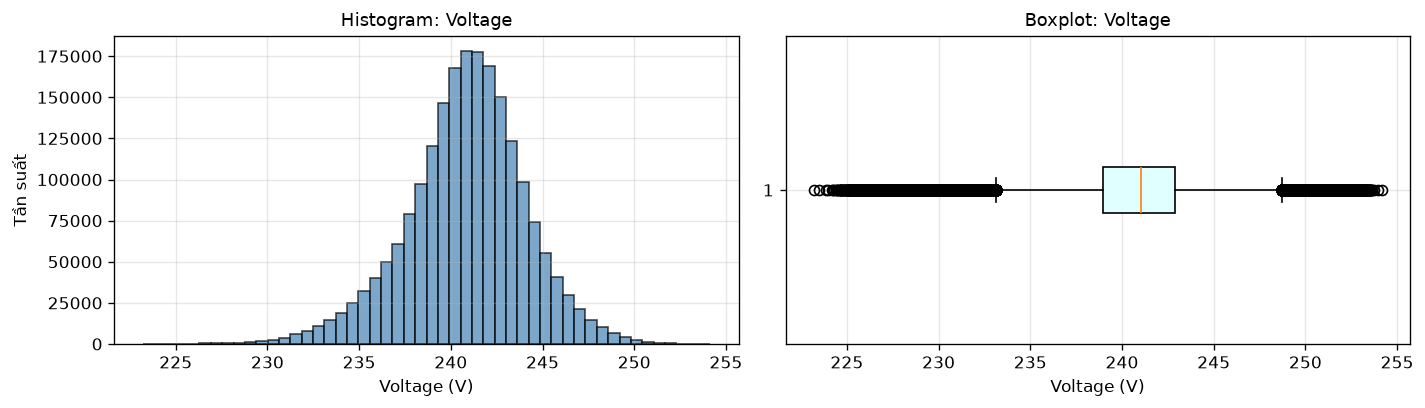

In [4]:
display(thong_ke(df_raw).round(3))

print("\nKIỂM THỬ HÀM TIỆN ÍCH: THỐNG KÊ CỘT 'Global_active_power'")
display(thong_ke_cot(df_raw, "Global_active_power").round(3))
print("\nKIỂM THỬ HÀM TIỆN ÍCH: VẼ PHÂN BỐ CỘT 'Voltage'")
ve_phan_bo(df_raw, "Voltage")

> **Nhận xét chuyên sâu về thống kê mô tả:**
> 1. **Tính hợp lệ của số lượng mẫu (`count`):** Cả 7 biến đo đều có đúng $2.049.280$ giá trị hợp lệ. Con số này nhỏ hơn tổng số dòng thời gian ($2.075.259$ phút) đúng $25.979$ dòng do chứa giá trị khuyết thiếu `NaN`. Sự bằng nhau về `count` này gợi ý rằng các cảm biến thường thiếu đồng thời (sẽ được kiểm chứng chặt chẽ ở Mục 6 bằng `isna().all()`).
> 2. **Công suất tác dụng (`Global_active_power`):**
>    - Trung bình đạt $1,092\text{ kW}$, cao hơn đáng kể so với trung vị $0,602\text{ kW}$.
>    - Hệ số lệch dương lớn ($\text{skew} = 1,786$) chỉ ra phân bố lệch phải rất mạnh: đúng $75\%$ số phút đo tiêu thụ dưới $1,528\text{ kW}$, trong khi đuôi trên kéo dài tới đỉnh cực đại $11,122\text{ kW}$.
>    - Tỷ lệ bằng 0 là $0,00\%$: Phụ tải nền tối thiểu luôn duy trì ở mức $0,076\text{ kW}$ (thiết bị cắm điện chờ, modem WiFi, tủ lạnh ở chế độ nghỉ).
> 3. **Công suất phản kháng (`Global_reactive_power`):**
>    - Trung bình $0,124\text{ kvar}$, $\text{skew} = 1,262$.
>    - Có tới $23,50\%$ số phút bằng 0, xuất hiện khi trong nhà chỉ có tải thuần trở hoạt động (bóng đèn dây tóc, lò sưởi điện cơ bản).
> 4. **Điện áp lưới (`Voltage`):**
>    - Rất ổn định với trung bình $240,84\text{ V}$, trung vị $241,01\text{ V}$, độ lệch chuẩn rất hẹp ($3,24\text{ V}$).
>    - Hệ số lệch $\text{skew} = -0,327$: Phân bố gần đối xứng nhưng hơi lệch nhẹ về phía trái do một số đợt sụt áp tức thời.
> 5. **Cường độ dòng điện (`Global_intensity`):**
>    - Dao động từ $0,2\text{ A}$ đến $48,4\text{ A}$, trung bình $4,63\text{ A}$, $\text{skew} = 1,849$. Biến thiên hoàn toàn đồng pha với công suất tác dụng ($P \approx V \cdot I$).
> 6. **Hành vi tiêu thụ của các nhóm thiết bị phụ tải (`Sub_metering`):**
>    - `Sub_metering_1` (Khu bếp): $91,75\%$ số phút bằng 0 ($\text{skew} = 5,945$), phân vị 75% vẫn là 0. Bếp chỉ bật vào giờ nấu nướng với đỉnh $\max = 88\text{ Wh/phút}$.
>    - `Sub_metering_2` (Khu giặt, sấy, tủ lạnh): $70,11\%$ số phút bằng 0 ($\text{skew} = 7,091$), phân vị 75% chỉ là $1\text{ Wh/phút}$ (có thể là chu kỳ làm lạnh cơ bản của tủ lạnh), đạt đỉnh $80\text{ Wh/phút}$ khi bật máy giặt/sấy.
>    - `Sub_metering_3` (Bình nước nóng & điều hòa): Trung bình đạt $6,458\text{ Wh/phút}$ — gấp **2,67 lần** hai nhóm trên gộp lại ($6,458 / (1,122 + 1,299) \approx 2,667$) và gấp 5,76 lần riêng nhóm bếp ($6,458 / 1,122 \approx 5,756$). Phân vị 75% là $17\text{ Wh/phút}$. Đây là nhóm tiêu thụ lớn nhất trong 3 nhóm phụ tải được đo riêng.
>    - **Cơ cấu năng lượng toàn hộ:** Trong toàn bộ dữ liệu, `Sub_metering_3` chiếm $35,5\%$, `Sub_metering_2` chiếm $7,1\%$, `Sub_metering_1` chiếm $6,2\%$. Còn lại **$51,2\%$ điện năng tiêu thụ thuộc về các thiết bị không đo riêng** (ví dụ có thể là hệ thống đèn chiếu sáng, tivi, máy tính, thiết bị sưởi không gắn cảm biến riêng).

In [5]:
# Tỷ lệ phút khu bếp hoạt động theo giờ (bỏ NaN trước để mẫu số chỉ gồm các phút có đo)
sm1 = df_raw["Sub_metering_1"].dropna()
bep_theo_gio = (sm1 > 0).groupby(sm1.index.hour).mean() * 100

print("TỶ LỆ PHÚT HOẠT ĐỘNG CỦA KHU BẾP THEO GIỜ (%)")
print(bep_theo_gio.loc[[4, 5, 8, 13, 14, 20, 21]].round(1).rename_axis("giờ").to_string())

TỶ LỆ PHÚT HOẠT ĐỘNG CỦA KHU BẾP THEO GIỜ (%)
giờ
4      0.4
5      0.2
8     14.5
13     9.9
14    14.2
20    19.3
21    27.5


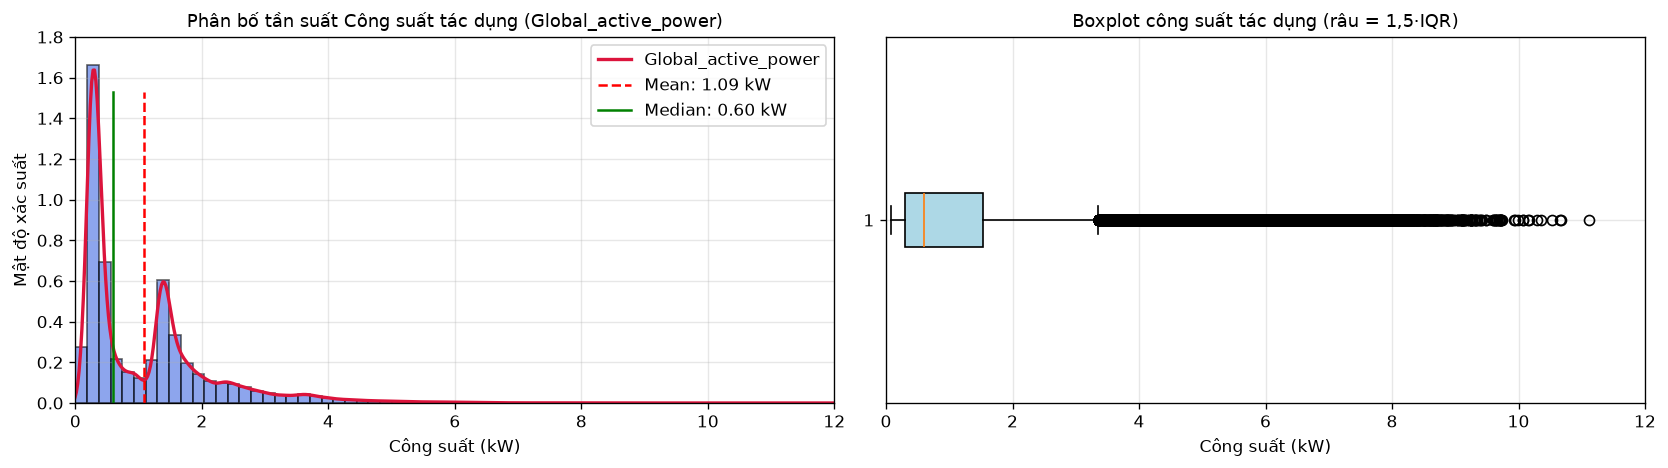

Ngưỡng râu trên (1.5*IQR): 3.358 kW
Số lượng điểm vượt râu trên: 94,907 (4.63%)


In [6]:
gap = df_raw["Global_active_power"].dropna()
_, upper_bound = iqr_fences(gap) # cận dưới < 0 nên chỉ có râu trên

fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(14, 4))

# Histogram + KDE
ax_hist.hist(gap, bins=60, range=(0, gap.max()), density=True, alpha=0.6, color="royalblue", edgecolor="black")
gap.plot(kind="kde", ax=ax_hist, color="crimson", lw=2)
ax_hist.axvline(gap.mean(), color="red", ls="--", ymax=0.85, label=f"Mean: {gap.mean():.2f} kW")
ax_hist.axvline(gap.median(), color="green", ls="-", ymax=0.85, label=f"Median: {gap.median():.2f} kW")
ax_hist.set(xlim=(0, 12), ylim=(0, 1.8))
set_labels(ax_hist, "Phân bố tần suất Công suất tác dụng (Global_active_power)", "Công suất (kW)", "Mật độ xác suất")
ax_hist.legend(loc="upper right")

ax_box.boxplot(gap, orientation="horizontal", patch_artist=True, boxprops={"facecolor": "lightblue"})
ax_box.set(xlim=(0, 12))
set_labels(ax_box, "Boxplot công suất tác dụng (râu = 1,5·IQR)", "Công suất (kW)", "")
plt.tight_layout()
plt.show()

outliers_gap = gap[gap > upper_bound]
print(f"Ngưỡng râu trên (1.5*IQR): {upper_bound:.3f} kW")
print(f"Số lượng điểm vượt râu trên: {len(outliers_gap):,} ({len(outliers_gap) / len(gap):.2%})")

> **Nhận xét biểu đồ phân bố công suất tác dụng:**
> * **Đặc tính phân bố:** Phân bố lệch phải rõ rệt. Khoảng $17,1\%$ số phút đo tập trung quanh vùng công suất nền $0,2 - 0,3\text{ kW}$. Đường KDE có hiện tượng tràn nhẹ sang vùng âm do tính chất làm mượt hạt nhân tại biên ($0\text{ kW}$), trong khi thực tế vật lý công suất luôn $\ge 0,076\text{ kW}$.
> * **Bản chất các điểm ngoại lai ($4,63\%$):** Có đúng **$94.907$ phút** ($4,63\%$) vượt qua ngưỡng râu trên của boxplot ($3,358\text{ kW}$). Các điểm này vươn dài tới $11,122\text{ kW}$. Đây là **các đỉnh phụ tải có thật trong sinh hoạt** (khi bật đồng thời lò nướng, máy sưởi, bình nước nóng), không phải lỗi cảm biến. Vì vậy, ta **giữ nguyên không cắt bỏ** để mô hình học cách dự báo đỉnh.

## 5. Phân bố các biến đo và Phân bố nhãn mục tiêu

### 5.1 Phân bố tần suất của cả 7 biến đo đạc (Lưới trục tung thang log)
Do các biến phụ tải có độ lệch phải lớn và tập trung dày đặc ở mức 0 hoặc mức nền thấp, biểu đồ tần suất được đặt ở thang logarit (`log scale`) trên trục tung để quan sát rõ toàn bộ phổ giá trị.


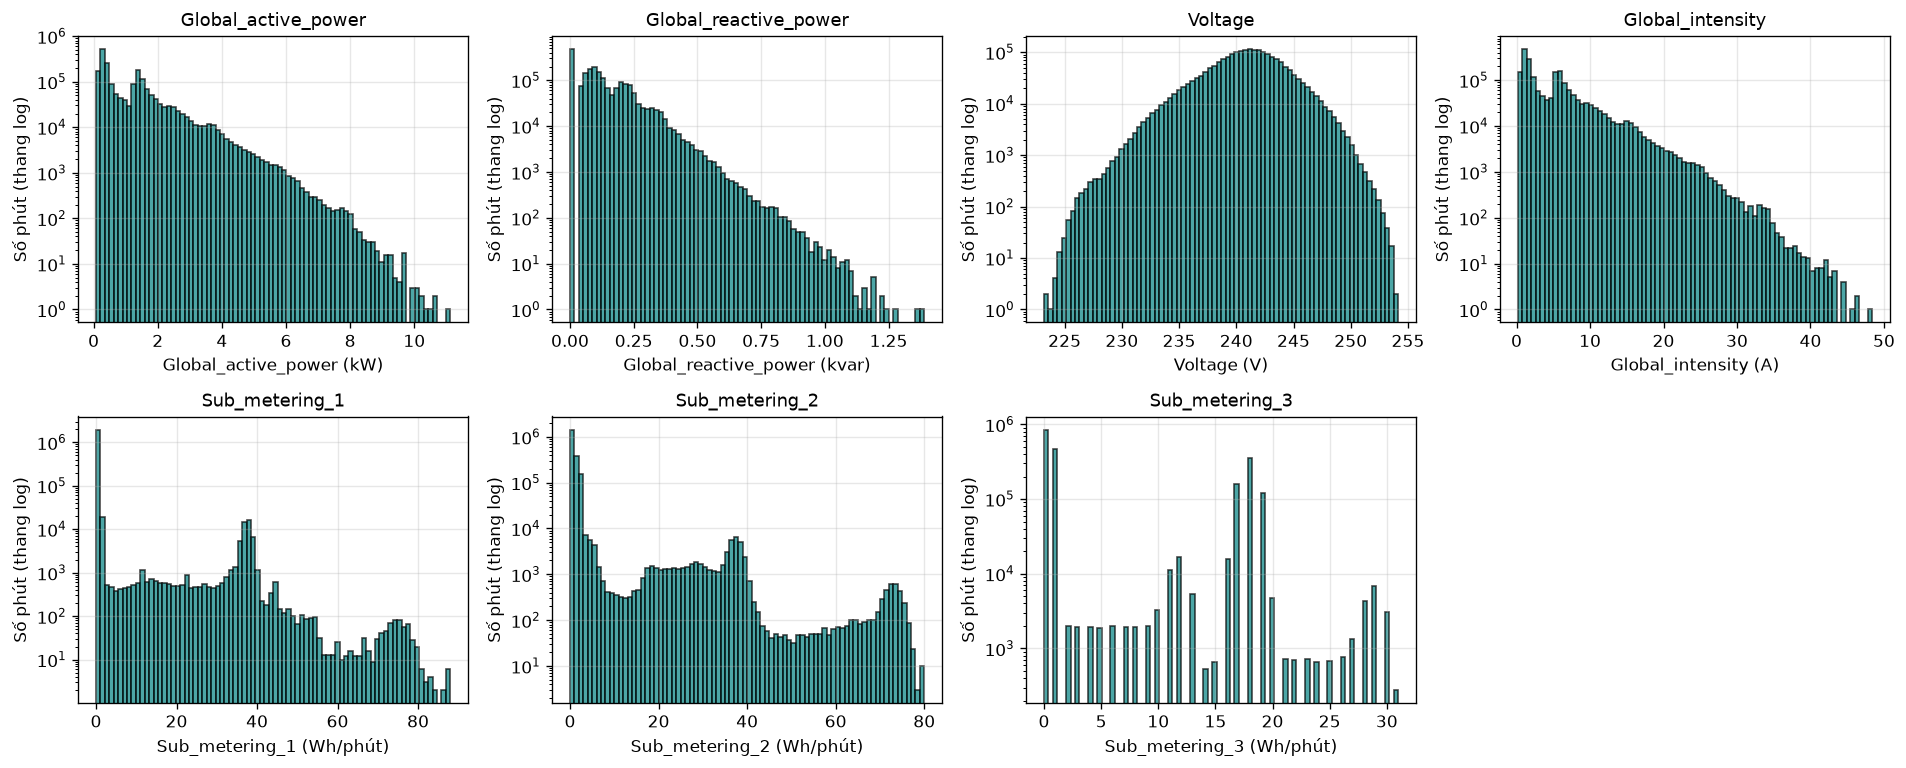

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, (col, unit) in zip(axes.flat, UNITS.items()):
    ax.hist(df_raw[col].dropna(), bins=80, color="teal", edgecolor="black", alpha=0.7)
    ax.set_yscale("log")
    set_labels(ax, col, f"{col} ({unit})", "Số phút (thang log)")
axes.flat[-1].axis("off") # ô thứ 8 còn thừa
plt.tight_layout()
plt.show()

> **Nhận xét phân bố 7 biến đo:**
> * **`Global_active_power` & `Global_intensity`:** Cùng có dạng phân bố suy giảm theo hàm mũ sau mức nền $0,2\text{ kW}$ / $1,4\text{ A}$.
> * **`Voltage`:** Phân bố gần đối xứng, hơi lệch trái quanh đỉnh $241\text{ V}$ ($\text{skew} = -0,327$), phản ánh sự ổn định cao của điện áp lưới điện Pháp.
> * **`Sub_metering_1` & `Sub_metering_2`:** Hầu hết số phút tập trung tại điểm 0 ($91,7\%$ và $70,1\%$), biểu thị tính chất gián đoạn cực mạnh của thiết bị nấu ăn và giặt ủi.
> * **`Sub_metering_3` có đặc tính hai cụm rõ rệt (Bimodal):**
>   - Cụm 1 ($0 - 1\text{ Wh/phút}$): Chiếm khoảng **$64,6\%$ số phút** (trạng thái bình nước nóng không gia nhiệt).
>   - Cụm 2 ($17 - 19\text{ Wh/phút}$): Chiếm khoảng **$30,7\%$ số phút** (giả thuyết là chu kỳ làm nóng của bình nước nóng hoặc điều hòa chạy hết công suất định mức).
>   $\implies$ Đặc trưng tiêu thụ rõ rệt dạng On/Off của thiết bị ổn nhiệt.

### 5.2 Xây dựng nhãn mục tiêu theo giờ (`energy_kwh`) và Khảo sát phân bố
* **Quy tắc tổng hợp:** Điện năng theo giờ $E_{\text{giờ}}\text{ [kWh]} = \text{mean}(P_i\text{ [kW]}) \times 1\text{ h}$.
* **Ngưỡng hợp lệ:** Áp dụng ngưỡng `THRESH = 54` phút/giờ (cho phép thiếu tối đa 10% số phút đo). Giờ có $< 54$ phút đo được gán là `NaN` (không nội suy nhãn).


In [8]:
THRESH = 54 # số phút có đo tối thiểu để một giờ được coi là hợp lệ

# Gộp dữ liệu phút thành bảng theo giờ; giờ có < thresh phút đo bị gán NaN (không nội suy)
def to_hourly(df_minute, thresh=THRESH):
    hourly = df_minute.resample("h").mean()
    out = pd.DataFrame({"n_valid": df_minute["Global_active_power"].resample("h").count(),
                        "energy_kwh": hourly["Global_active_power"]}) # kW × 1 h = kWh (nhãn)
    for i in (1, 2, 3): # Wh/phút × 60 / 1000 = kWh
        out[f"sub{i}_kwh"] = hourly[f"Sub_metering_{i}"] * 60 / 1000
    out["other_kwh"] = out["energy_kwh"] - out[["sub1_kwh", "sub2_kwh", "sub3_kwh"]].sum(axis=1)
    out["voltage_mean"] = hourly["Voltage"]
    out.loc[out["n_valid"] < thresh, out.columns.drop("n_valid")] = np.nan
    return out


df_hourly = to_hourly(df_raw)
energy_hourly, n_valid_minutes = df_hourly["energy_kwh"], df_hourly["n_valid"]
valid = energy_hourly.notna()

print("THỐNG SỐ CHUỖI ĐIỆN NĂNG THEO GIỜ (TARGET)")
print(f"Tổng số giờ trên lưới liên tục : {len(energy_hourly):,}")
print(f"Số giờ hợp lệ (>= {THRESH} phút)    : {valid.sum():,} ({valid.mean():.2%})")
print(f"Số giờ bị gán NaN do thiếu     : {(~valid).sum():,} ({(~valid).mean():.2%})")
print(f"Trung bình / Độ lệch chuẩn     : {energy_hourly.mean():.3f} / {energy_hourly.std():.3f} kWh | Skew: {energy_hourly.skew():.3f}")
print(f"Min / Max / Phân vị 1%         : {energy_hourly.min():.3f} / {energy_hourly.max():.3f} / {energy_hourly.quantile(0.01):.3f} kWh")

THỐNG SỐ CHUỖI ĐIỆN NĂNG THEO GIỜ (TARGET)
Tổng số giờ trên lưới liên tục : 34,589
Số giờ hợp lệ (>= 54 phút)    : 34,143 (98.71%)
Số giờ bị gán NaN do thiếu     : 446 (1.29%)
Trung bình / Độ lệch chuẩn     : 1.092 / 0.898 kWh | Skew: 1.298
Min / Max / Phân vị 1%         : 0.124 / 6.561 / 0.170 kWh


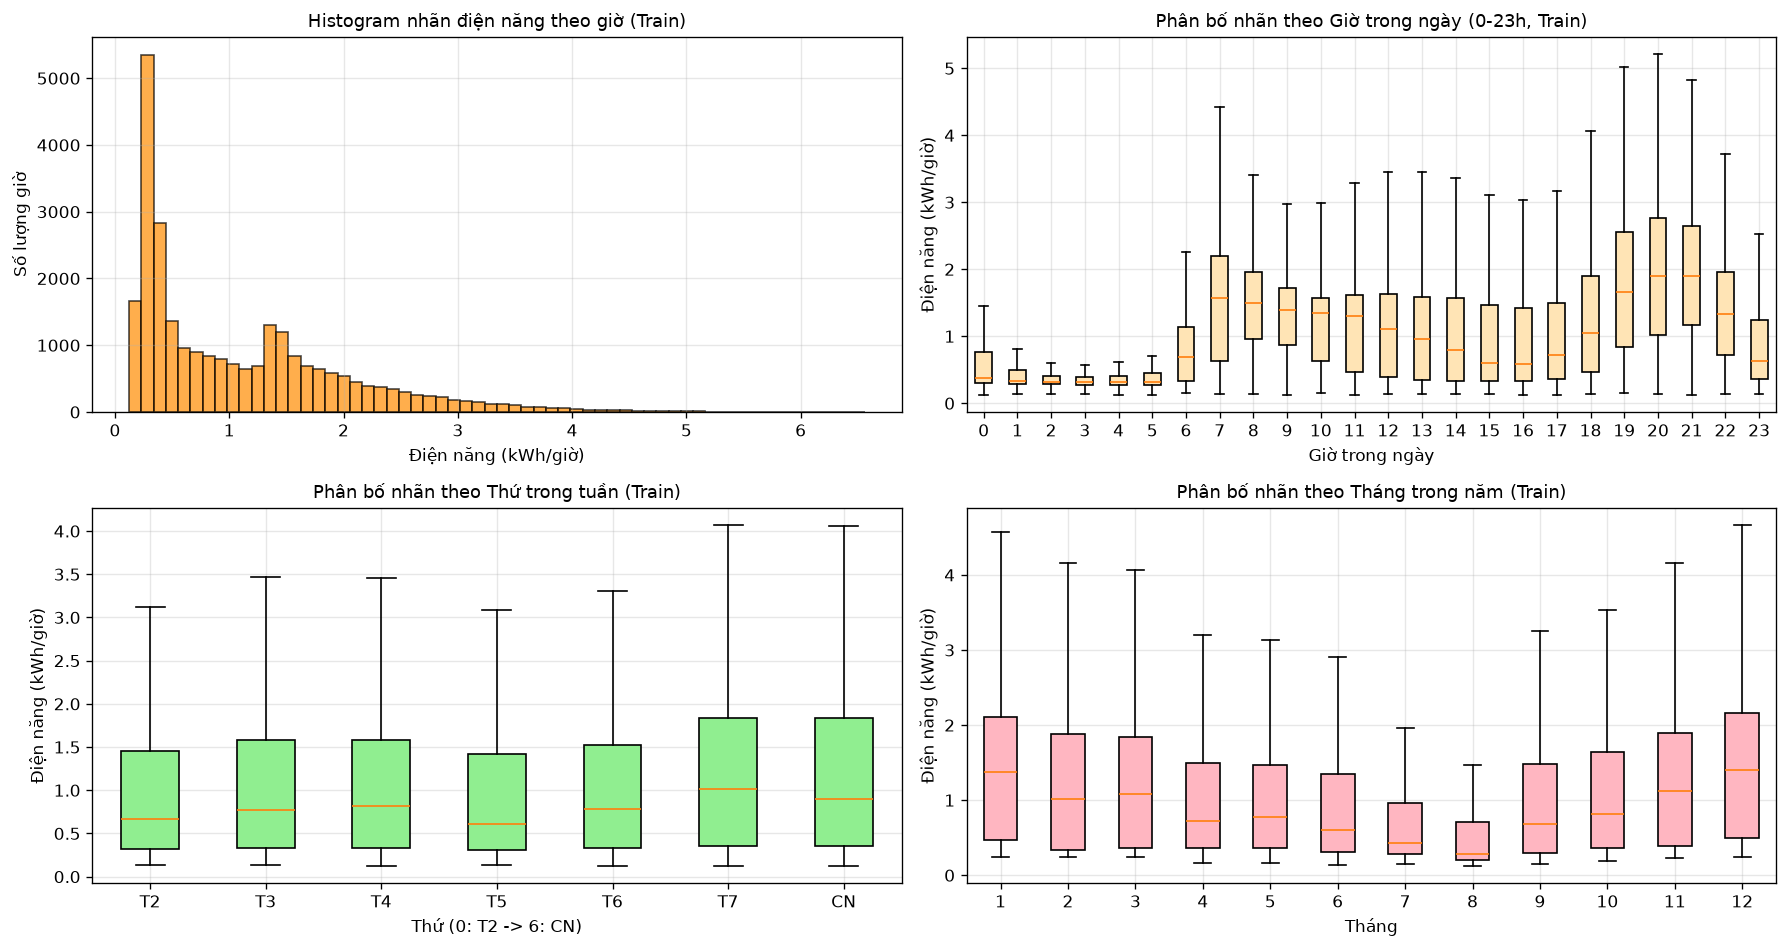

THÔNG SỐ ĐỐI CHIẾU PHÂN BỐ NHÃN (TRAIN)
- Trung vị lúc 3-4h sáng : 0.315 kWh
- Trung vị lúc 20h tối   : 1.904 kWh (IQR: 1.02 - 2.77)
- Độ lệch chuẩn khung tối: 19h (1.154), 20h (1.176), 21h (1.102)
- Trung vị theo thứ      : T2 (0.665), T7 (1.014), CN (0.904)
- Trung vị theo tháng    : Tháng 12 (1.398), Tháng 8 (0.289)
- Ngưỡng râu trên nhãn train: 3.494 kWh; Tỷ lệ giờ vượt râu: 2.26%


In [9]:
train_energy = energy_hourly[energy_hourly.index < "2010-01-01"].dropna()      # nhãn tập TRAIN
by_hour, by_dow, by_month = (train_energy.groupby(key) for key in
                             (train_energy.index.hour, train_energy.index.day_of_week, train_energy.index.month))

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes[0, 0].hist(train_energy, bins=60, color="darkorange", edgecolor="black", alpha=0.7)
set_labels(axes[0, 0], "Histogram nhãn điện năng theo giờ (Train)", "Điện năng (kWh/giờ)", "Số lượng giờ")

# (nhóm, ô vẽ, nhãn trục x, nhãn các hộp, màu, tiêu đề)
box_specs = [
    (by_hour, axes[0, 1], "Giờ trong ngày", range(24), "moccasin", "Phân bố nhãn theo Giờ trong ngày (0-23h, Train)"),
    (by_dow, axes[1, 0], "Thứ (0: T2 -> 6: CN)", ["T2", "T3", "T4", "T5", "T6", "T7", "CN"], "lightgreen", "Phân bố nhãn theo Thứ trong tuần (Train)"),
    (by_month, axes[1, 1], "Tháng", range(1, 13), "lightpink", "Phân bố nhãn theo Tháng trong năm (Train)"),
]
for groups, ax, xlabel, ticklabels, color, title in box_specs:
    ax.boxplot([g.values for _, g in groups], tick_labels=[str(t) for t in ticklabels], showfliers=False,
               patch_artist=True, boxprops={"facecolor": color})
    set_labels(ax, title, xlabel, "Điện năng (kWh/giờ)")
plt.tight_layout()
plt.show()

# Các thông số định lượng phục vụ nhận xét
hour20 = by_hour.get_group(20)
q25_20, q75_20 = hour20.quantile([0.25, 0.75])
std_hour, med_dow, med_month = by_hour.std(), by_dow.median(), by_month.median()
_, whisker_y = iqr_fences(train_energy)

print("THÔNG SỐ ĐỐI CHIẾU PHÂN BỐ NHÃN (TRAIN)")
print(f"- Trung vị lúc 3-4h sáng : {train_energy[train_energy.index.hour.isin([3, 4])].median():.3f} kWh")
print(f"- Trung vị lúc 20h tối   : {hour20.median():.3f} kWh (IQR: {q25_20:.2f} - {q75_20:.2f})")
print("- Độ lệch chuẩn khung tối: " + ", ".join(f"{h}h ({std_hour.loc[h]:.3f})" for h in (19, 20, 21)))
print(f"- Trung vị theo thứ      : T2 ({med_dow.loc[0]:.3f}), T7 ({med_dow.loc[5]:.3f}), CN ({med_dow.loc[6]:.3f})")
print(f"- Trung vị theo tháng    : Tháng 12 ({med_month.loc[12]:.3f}), Tháng 8 ({med_month.loc[8]:.3f})")
print(f"- Ngưỡng râu trên nhãn train: {whisker_y:.3f} kWh; Tỷ lệ giờ vượt râu: {(train_energy > whisker_y).mean():.2%}")

> **Nhận xét phân bố nhãn và hệ quả cho mô hình học máy:**
> 1. **Dạng phân bố đa đỉnh:** Phân bố nhãn có đỉnh cao nhất ở vùng tải nền khoảng $0,23\text{ kWh}$ (~5.350 giờ) và **đỉnh thứ hai** ở khoảng $1,4\text{ kWh}$ (~1.300 giờ).
> 2. **Biến động cực mạnh theo chu kỳ 24 giờ:**
>    - Mức tiêu thụ thấp nhất lúc 3–4 giờ sáng (trung vị $\approx 0,32\text{ kWh}$).
>    - Đạt đỉnh cao nhất vào 20 giờ tối (trung vị $\approx 1,90\text{ kWh}$, dải phân tán $1,02 - 2,77\text{ kWh}$).
>    - Khung 19–21 giờ có độ lệch chuẩn lớn nhất (20h: $1,176$; 19h: $1,154$; 21h: $1,102$) $\implies$ Khung giờ tối là vùng khó dự báo nhất.
>    $\implies$ **Hệ quả cho mô hình:** Bắt buộc phải có đặc trưng trễ cùng giờ hôm trước (`same_hour_prev_day`) và mã hóa đặc trưng giờ (`hour`).
> 3. **Tính quy luật theo tuần và theo mùa:**
>    - Cuối tuần (T7, CN) có trung vị tiêu thụ ($1,014$ và $0,904\text{ kWh}$) cao hơn rõ so với các ngày trong tuần ($0,62 - 0,82\text{ kWh}$), có thể do các thành viên ở nhà sinh hoạt nhiều hơn.
>    - Tháng 12 tiêu thụ cao nhất (trung vị $\approx 1,398\text{ kWh}$), có thể do nhu cầu sưởi ấm trong mùa đông Pháp. Ngược lại, tháng 8 giảm sâu bất thường (trung vị chỉ $\approx 0,289\text{ kWh}$), có thể do gia đình đi nghỉ hè.
>    $\implies$ **Hệ quả cho mô hình:** Cần bổ sung cờ cuối tuần `is_weekend` và đặc trưng tháng `month`.
> 4. **Vấn đề mất cân bằng trong bài toán hồi quy:**
>    - Đây là bài toán hồi quy (không phân lớp), tuy nhiên tồn tại hiện tượng mất cân bằng theo dải giá trị: chỉ có khoảng **$2,26\%$ số giờ** (tập Train) vượt ngưỡng râu trên ($3,49\text{ kWh}$).
>    $\implies$ **Hệ quả:** Nếu sử dụng hàm mất mát $\text{MSE}$, mô hình sẽ bị kéo lệch nghiêm trọng bởi các đỉnh này; do đó lựa chọn **$\text{MAE}$** làm chỉ số tối ưu chính là hoàn toàn phù hợp.

## 6. Phát hiện và Định lượng vấn đề chất lượng dữ liệu

Mục này thực hiện kiểm tra toàn diện 9 khía cạnh chất lượng dữ liệu trên tập dữ liệu thô. Mọi kết quả định lượng được tính toán trực tiếp từ các biến trong notebook.


In [10]:
# Ký tự '?' trong file văn bản gốc
with open(TXT_PATH, encoding="utf-8") as f:
    count_question_marks = sum(line.count("?") for line in f)

# Trùng lặp và tính liên tục của mốc thời gian
dup_timestamps = df_raw.index.duplicated().sum()
full_timeline = pd.date_range(df_raw.index.min(), df_raw.index.max(), freq="min")
missing_timestamps = len(full_timeline.difference(df_raw.index))

# Dòng thiếu hoàn toàn / thiếu một phần
nan_rows_all, nan_rows_any = df_raw.isna().all(axis=1).sum(), df_raw.isna().any(axis=1).sum()
pct_missing_rows = nan_rows_any / len(df_raw) * 100

# Các khối thiếu liên tiếp (run-length): mỗi khối = một dãy phút liền nhau cùng trạng thái NaN / không NaN
is_nan = df_raw["Global_active_power"].isna()
block_id = (is_nan != is_nan.shift()).cumsum()
df_gaps = (is_nan.index.to_series().groupby(block_id).agg(bat_dau="first", so_phut="size")
           .loc[is_nan.groupby(block_id).first()] # chỉ giữ các khối là NaN
           .sort_values("so_phut", ascending=False))
df_gaps["so_gio"] = (df_gaps["so_phut"] / 60).round(1)
long_gaps = df_gaps[df_gaps["so_phut"] > 1440] # khối dài hơn 1 ngày
pct_missing_in_long_runs = long_gaps["so_phut"].sum() / nan_rows_any * 100


# Ngoại lai theo 1,5·IQR cho cả 7 cột
def tinh_ngoai_lai(s):
    s = s.dropna()
    (lower, upper), (q1, q3) = iqr_fences(s), s.quantile([0.25, 0.75])
    n = int(((s < lower) | (s > upper)).sum())
    return pd.Series({"Q1": q1, "Q3": q3, "Can_duoi": lower, "Can_tren": upper,
                      "So_ngoai_lai": n, "Ty_le_ngoai_lai_%": n / len(s) * 100})


table_outliers = df_raw.apply(tinh_ngoai_lai).T.round(3)
table_outliers["So_ngoai_lai"] = table_outliers["So_ngoai_lai"].astype(int)

# 6. Tính hợp lý vật lý và nhất quán đơn vị (điện năng "còn lại" = tổng - ba nhóm đo riêng, đơn vị Wh/phút)
count_negative_values = (df_raw < 0).sum().sum()
voltage_over_253v = int((df_raw["Voltage"] > 253).sum())
e_other = df_raw["Global_active_power"] * 1000 / 60 - df_raw[["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]].sum(axis=1)
pct_negative_other, min_negative_other = (e_other.dropna() < 0).mean() * 100, e_other.min()

# 7. Rò rỉ: tương quan giữa công suất và V·I
corr_gap_intensity = df_raw["Global_active_power"].corr(df_raw["Voltage"] * df_raw["Global_intensity"] / 1000)

print(f"Tổng số dấu '?': {count_question_marks:,}")
print(f"Số dòng thiếu đồng thời cả 7 biến: {nan_rows_all:,} (isna.any = {nan_rows_any:,})")
print(f"Tổng số khối thiếu: {len(df_gaps)}, Khối > 1 ngày: {len(long_gaps)} ({pct_missing_in_long_runs:.1f}% phút thiếu)")
print(f"Số phút điện áp > 253V: {voltage_over_253v}")
print(f"Tương quan GAP và V*I/1000: {corr_gap_intensity:.5f}")

Tổng số dấu '?': 155,874
Số dòng thiếu đồng thời cả 7 biến: 25,979 (isna.any = 25,979)
Tổng số khối thiếu: 71, Khối > 1 ngày: 6 (94.9% phút thiếu)
Số phút điện áp > 253V: 57
Tương quan GAP và V*I/1000: 0.99909


In [11]:
print(f"DANH SÁCH {len(long_gaps)} KHỐI THIẾU DỮ LIỆU KÉO DÀI TRÊN 1 NGÀY")
display(long_gaps.reset_index(drop=True))

DANH SÁCH 6 KHỐI THIẾU DỮ LIỆU KÉO DÀI TRÊN 1 NGÀY


,bat_dau,so_phut,so_gio
0,2010-08-17 21:02:00,7226,120.4
1,2010-09-25 03:56:00,5237,87.3
2,2007-04-28 00:21:00,3723,62.0
3,2009-06-13 00:30:00,3305,55.1
4,2010-01-12 14:53:00,3129,52.2
5,2010-03-20 03:52:00,2027,33.8


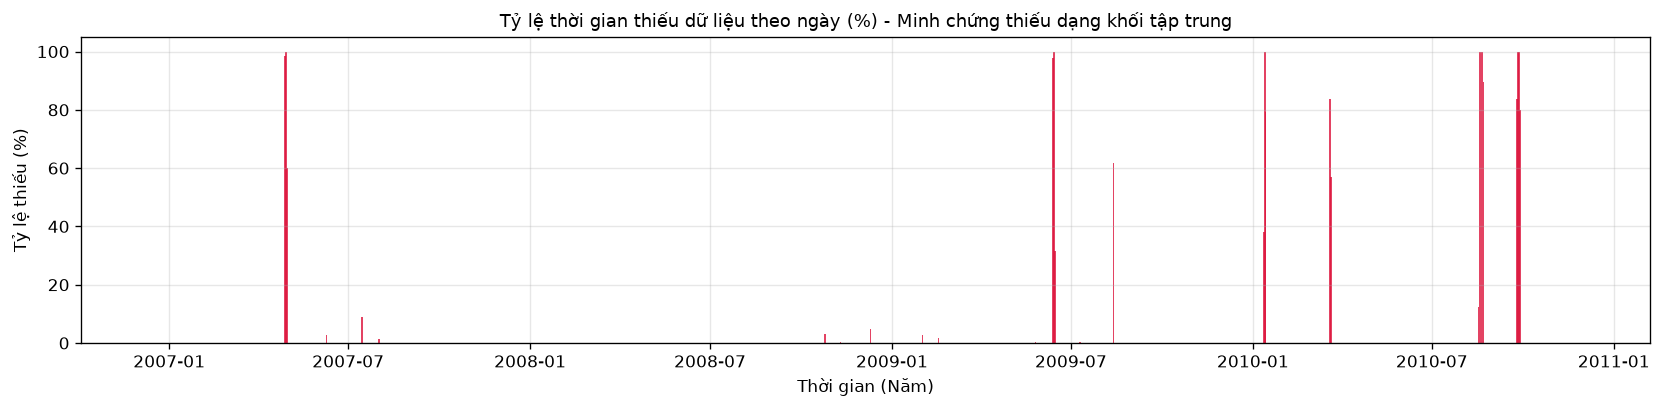

In [12]:
missing_rate_daily = df_raw["Global_active_power"].isna().resample("D").mean() * 100

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(missing_rate_daily.index, missing_rate_daily.values, width=1.5, color="crimson", alpha=0.8)
ax.set_ylim(0, 105)
set_labels(ax, "Tỷ lệ thời gian thiếu dữ liệu theo ngày (%) - Minh chứng thiếu dạng khối tập trung", "Thời gian (Năm)", "Tỷ lệ thiếu (%)")
plt.tight_layout()
plt.show()

> **Nhận xét biểu đồ dữ liệu thiếu theo ngày:**
> * Dữ liệu thiếu hoàn toàn **không phân tán rải rác ngẫu nhiên** (không phải Missing Completely At Random theo từng phút đơn lẻ).
> * Toàn bộ $25.979$ phút thiếu tập trung thành **$71$ khối thiếu dữ liệu liên tục**. Đáng chú ý, chỉ riêng **6 khối thiếu dài trên 1 ngày** đã chiếm tới **$94,9\%$** tổng lượng dữ liệu bị thiếu. Khối dài nhất lên tới $120,4\text{ giờ}$ ($7.226\text{ phút}$, hơn 5 ngày liên tục từ ngày 17/08/2010). Có thể do sự cố đường truyền đo đạc hoặc thiết bị ghi dữ liệu bị ngắt kết nối.
> * Đáng chú ý, 4 trong số 6 khối thiếu lớn nhất lại rơi vào năm 2010 (tập Test tương lai) $\implies$ Khẳng định tầm quan trọng của chiến lược tiền xử lý không được làm rò rỉ thông tin tương lai.

In [13]:
# Mọi con số đều lấy từ các biến đã tính ở trên
gap_row, sm1_row = table_outliers.loc["Global_active_power"], table_outliers.loc["Sub_metering_1"]
voltage_over_pct = voltage_over_253v / df_raw["Voltage"].count() * 100
n_long_2010 = (long_gaps["bat_dau"].dt.year == 2010).sum()
longest = df_gaps.iloc[0]

quality_rows = [
    ("1. Sai định dạng ký tự lạ", f"{count_question_marks:,} ô ký tự '?'", f"{nan_rows_any:,} dòng x 6 cột",
     "Ký tự '?' làm 6 cột số bị đọc thành kiểu chuỗi (object). Cột SM3 để trống.",
     "Gây lỗi toàn bộ các phép tính toán số học nếu không khai báo na_values."),
    ("2. Bản ghi trùng lặp mốc giờ", f"{dup_timestamps} bản ghi trùng", f"{dup_timestamps / len(df_raw):.2%}",
     "Kiểm tra bằng df.index.duplicated(). Không có mốc thời gian nào bị trùng.", "Không có rủi ro trùng lặp dữ liệu."),
    ("3. Mốc thời gian bị gián đoạn", f"{missing_timestamps} mốc thời gian", f"{missing_timestamps / len(full_timeline):.2%}",
     "So khớp với lưới thời gian chuẩn bước 1 phút: Lưới thời gian liên tục 100%.", "Đảm bảo tính đều đặn tuyệt đối của chuỗi thời gian."),
    ("4. Dữ liệu khuyết thiếu (NaN)", f"{nan_rows_any:,} dòng thiếu", f"{pct_missing_rows:.3f}%",
     f"Đúng {nan_rows_all:,} dòng thiếu trọn vẹn cả 7 biến (thiếu một phần: {nan_rows_any - nan_rows_all} dòng).", "Mất thông tin tại các khối dài ngày."),
    ("5. Cấu trúc thiếu dạng khối", f"{len(df_gaps)} khối; {len(long_gaps)} khối > 1 ngày", f"{pct_missing_in_long_runs:.1f}% số phút thiếu",
     f"Khối dài nhất {longest['so_gio']} giờ ({longest['bat_dau']:%d/%m/%Y}). {n_long_2010} khối dài rơi vào năm 2010.",
     "Không thể nội suy tuyến tính (sẽ tạo dữ liệu giả rò rỉ tương lai)."),
    ("6. Giá trị ngoại lai (1.5*IQR)", f"{int(gap_row['So_ngoai_lai']):,} phút", f"{gap_row['Ty_le_ngoai_lai_%']:.2f}% (GAP)",
     f"SM1 có {sm1_row['Ty_le_ngoai_lai_%']:.2f}% vượt IQR; SM3 có 0% ngoại lai (Q3=17, dải hẹp).", "Là đỉnh tiêu thụ thật, không phải lỗi cảm biến."),
    ("7. Tính hợp lý vật lý", f"{count_negative_values} âm; {voltage_over_253v} phút áp cao", f"Áp cao: {voltage_over_pct:.3f}%",
     f"{count_negative_values} giá trị âm; {voltage_over_253v} phút điện áp > 253V (253V = 230V + 10% theo tiêu chuẩn NF EN 50160).",
     "Cảm biến vận hành vật lý chuẩn xác."),
    ("8. Nhất quán đơn vị đo", f"{pct_negative_other:.2f}% phút e_other < 0", f"Min: {min_negative_other:.1f} Wh/phút",
     f"GAP*1000/60 nhỏ hơn tổng 3 nhóm phụ tải ở ~{pct_negative_other:.2f}% số phút do lệch xung nhịp cảm biến.",
     "Sai số làm tròn xung đo ở mức vi mô, không đáng kể."),
    ("9. Nguy cơ Rò rỉ dữ liệu", f"Tương quan r = {corr_gap_intensity:.5f}", f"r² = {corr_gap_intensity ** 2:.4f}",
     "Global_intensity đo cùng lúc với GAP và tương quan 0,999.", "Nếu đưa vào làm đặc trưng sẽ rò rỉ đáp án, mô hình gian lận."),
]
summary_quality_table = pd.DataFrame(quality_rows, columns=["Vấn đề chất lượng", "Số lượng định lượng", "Tỷ lệ", "Mô tả chi tiết", "Rủi ro / Ảnh hưởng"])
display(summary_quality_table)

,Vấn đề chất lượng,Số lượng định lượng,Tỷ lệ,Mô tả chi tiết,Rủi ro / Ảnh hưởng
0,1. Sai định dạng ký tự lạ,"155,874 ô ký tự '?'","25,979 dòng x 6 cột",Ký tự '?' làm 6 cột số bị đọc thành kiểu chuỗi...,Gây lỗi toàn bộ các phép tính toán số học nếu ...
1,2. Bản ghi trùng lặp mốc giờ,0 bản ghi trùng,0.00%,Kiểm tra bằng df.index.duplicated(). Không có ...,Không có rủi ro trùng lặp dữ liệu.
2,3. Mốc thời gian bị gián đoạn,0 mốc thời gian,0.00%,So khớp với lưới thời gian chuẩn bước 1 phút: ...,Đảm bảo tính đều đặn tuyệt đối của chuỗi thời ...
3,4. Dữ liệu khuyết thiếu (NaN),"25,979 dòng thiếu",1.252%,"Đúng 25,979 dòng thiếu trọn vẹn cả 7 biến (thi...",Mất thông tin tại các khối dài ngày.
4,5. Cấu trúc thiếu dạng khối,71 khối; 6 khối > 1 ngày,94.9% số phút thiếu,Khối dài nhất 120.4 giờ (17/08/2010). 4 khối d...,Không thể nội suy tuyến tính (sẽ tạo dữ liệu g...
5,6. Giá trị ngoại lai (1.5*IQR),"94,907 phút",4.63% (GAP),SM1 có 8.25% vượt IQR; SM3 có 0% ngoại lai (Q3...,"Là đỉnh tiêu thụ thật, không phải lỗi cảm biến."
6,7. Tính hợp lý vật lý,0 âm; 57 phút áp cao,Áp cao: 0.003%,0 giá trị âm; 57 phút điện áp > 253V (253V = 2...,Cảm biến vận hành vật lý chuẩn xác.
7,8. Nhất quán đơn vị đo,0.05% phút e_other < 0,Min: -2.4 Wh/phút,GAP*1000/60 nhỏ hơn tổng 3 nhóm phụ tải ở ~0.0...,"Sai số làm tròn xung đo ở mức vi mô, không đán..."
8,9. Nguy cơ Rò rỉ dữ liệu,Tương quan r = 0.99909,r² = 0.9982,Global_intensity đo cùng lúc với GAP và tương ...,"Nếu đưa vào làm đặc trưng sẽ rò rỉ đáp án, mô ..."


## 7. Xử lý vấn đề chất lượng và So sánh trước – sau

### 7.1 Bảng quyết định xử lý chất lượng dữ liệu

| Vấn đề | Quyết định xử lý | Lý do kỹ thuật và Các phương án đã cân nhắc |
|---|---|---|
| **Ký tự lạ `?`** | `read_csv(na_values=["?", ""])` + ép `float64` | Xử lý triệt để ký hiệu quy ước của UCI. *Phương án loại bỏ:* Không thay bằng 0 vì hộ luôn có tải nền $\min = 0,076\text{ kW}$. |
| **Dữ liệu thiếu (Target)** | Tổng hợp theo giờ với ngưỡng $\ge 54$ phút/giờ; giữ `NaN` nếu không đủ | *Không nội suy (Interpolation):* Các khối thiếu kéo dài tới 5 ngày; nếu nội suy sẽ dùng dữ liệu tương lai sau khối để điền vào quá khứ $\implies$ Rò rỉ dữ liệu và làm phẳng giả tạo các biến động.<br>*Không xóa dòng:* Xóa dòng sẽ phá vỡ tính liên tục của lưới thời gian, làm hỏng các phép tính lag và rolling. |
| **Dữ liệu thiếu (Feature)** | Điền `median` **bên trong Pipeline scikit-learn, chỉ fit trên tập Train** | Điền median có tính bền vững (robust) cao với phân bố lệch phải; so với mean không bị kéo lệch bởi các đỉnh công suất cao. |
| **Ngoại lai (Outliers)** | **Giữ nguyên toàn bộ**, không cắt tỉa (winsorize/clip) | Các đỉnh công suất là hành vi sử dụng thiết bị thật cần học cách dự báo. Cắt bỏ sẽ làm sai lệch tổng điện năng tiêu thụ và che giấu sai số ở giờ cao điểm. Sử dụng chỉ số MAE để hạn chế độ nhạy với ngoại lai. |
| **Rò rỉ dữ liệu** | **Loại bỏ hoàn toàn** `Global_intensity` và `Voltage` đồng thời | Cường độ dòng điện $I$ và điện áp $V$ đo đồng thời với nhãn tại thời điểm $t+h$. Tại thời điểm dự báo $t$, các đại lượng này ở tương lai chưa hề được biết. |
| **Mất cân bằng dữ liệu** | Không áp dụng các kỹ thuật oversampling/SMOTE | Áp dụng SMOTE trên chuỗi thời gian sẽ phá vỡ thứ tự thời gian. Thay vào đó, phân tích đánh giá sai số riêng theo khung giờ cao điểm và theo tháng. |

### 7.2 Thử nghiệm độ nhạy của ngưỡng số phút hợp lệ trong một giờ
Khảo sát số lượng giờ hợp lệ thu được khi thay đổi ngưỡng yêu cầu số phút có đo trong giờ (`THRESH = 60, 54, 30, 1`):


In [14]:
total_hours = len(n_valid_minutes)
threshold_table = pd.DataFrame([(t, (n_valid_minutes >= t).sum()) for t in (60, 54, 30, 1)],
                               columns=["Nguong_phut_toi_thieu", "So_gio_hop_le"])
threshold_table["Ty_le_hop_le_%"] = (threshold_table["So_gio_hop_le"] / total_hours * 100).round(2)
threshold_table["So_gio_bi_loai_NaN"] = total_hours - threshold_table["So_gio_hop_le"]
display(threshold_table)

,Nguong_phut_toi_thieu,So_gio_hop_le,Ty_le_hop_le_%,So_gio_bi_loai_NaN
0,60,34085,98.54,504
1,54,34143,98.71,446
2,30,34157,98.75,432
3,1,34168,98.78,421


> **Nhận xét thử nghiệm ngưỡng:**
> * Thay đổi ngưỡng từ $60$ phút (yêu cầu tuyệt đối) xuống $1$ phút (chỉ cần 1 phút có đo) thì số giờ hợp lệ chỉ chênh lệch vỏn vẹn **$83$ giờ** ($34.085 \to 34.168$, tức chỉ biến động $0,24\%$).
> * Lý do: Hầu hết các phút thiếu tập trung trong các khối thiếu dữ liệu kéo dài nhiều ngày (trong đó có 421 giờ thiếu 100% không có phút nào; 25 giờ có 1–53 phút đo).
> * **Lựa chọn ngưỡng 54 phút:** Cho phép thiếu tối đa $10\%$ số phút đo ($6$ phút). Ngưỡng này giúp giữ lại được **$58$ giờ** có mất dữ liệu ngắn ngủi nhưng giá trị trung bình vẫn đại diện chuẩn xác cho mức tiêu thụ của cả giờ đó.

### 7.3 Lưu bảng dữ liệu theo giờ (`hourly.parquet`) và Bảng so sánh trước – sau


In [15]:
# df_hourly đã được tạo ở mục 5.2 bằng to_hourly(); lưu ra file cache để notebook 02 dùng
save_processed(df_hourly, "hourly.parquet")

Đã lưu: ..\data\processed\hourly.parquet (1.10 MB)


In [16]:
def tom_tat(s):
    return {"Số dòng": f"{len(s):,}", "Số dòng thiếu (NaN)": f"{s.isna().sum():,}", "Tỷ lệ thiếu": f"{s.isna().mean():.3%}",
            "Trung bình": f"{s.mean():.3f}", "Độ lệch chuẩn": f"{s.std():.3f}", "Trung vị": f"{s.median():.3f}",
            "Min": f"{s.min():.3f}", "Max": f"{s.max():.3f}", "Skew": f"{s.skew():.2f}"}


before_gap, after_energy = df_raw["Global_active_power"], df_hourly["energy_kwh"]
table_before_after = pd.DataFrame({"Trước (GAP theo phút, kW)": tom_tat(before_gap),
                                   "Sau (energy_kwh theo giờ, kWh)": tom_tat(after_energy)})
display(table_before_after)

,"Trước (GAP theo phút, kW)","Sau (energy_kwh theo giờ, kWh)"
Số dòng,"2,075,259","34,589"
Số dòng thiếu (NaN),"25,979",446
Tỷ lệ thiếu,1.252%,1.289%
Trung bình,1.092,1.092
Độ lệch chuẩn,1.057,0.898
Trung vị,0.602,0.803
Min,0.076,0.124
Max,11.122,6.561
Skew,1.79,1.30


> **Nhận xét so sánh trước – sau xử lý:**
> 1. **Bảo toàn điện năng xấp xỉ:** Giá trị trung bình giữ gần như nguyên vẹn ở mức **$1,092$** ($1,0916\text{ kW}$ công suất trung bình phút quy đổi thành $1,0915\text{ kWh}$ điện năng/giờ).
> 2. **Làm mượt các dao động ngắn hạn:**
>    - Độ lệch chuẩn giảm từ $1,057$ xuống $0,898$ (giảm $15\%$).
>    - Đỉnh tối đa giảm từ $11,122\text{ kW}$ xuống $6,561\text{ kWh}$ do phép lấy trung bình theo giờ đã làm mượt các dao động kéo dài vài phút của các thiết bị công suất cao.
>    - Hệ số lệch $\text{skew}$ giảm từ $1,79$ xuống $1,30$, đưa phân bố về gần hơn với phân bố chuẩn.
> 3. **Tỷ lệ thiếu:** Tăng nhẹ từ $1,252\%$ lên $1,289\%$ (từ 25.979 phút lên 446 giờ bị gán NaN), do những giờ thiếu từ 7 phút trở lên ($< 54$ phút hợp lệ) bị loại bỏ có chủ đích để bảo vệ độ chính xác của nhãn.

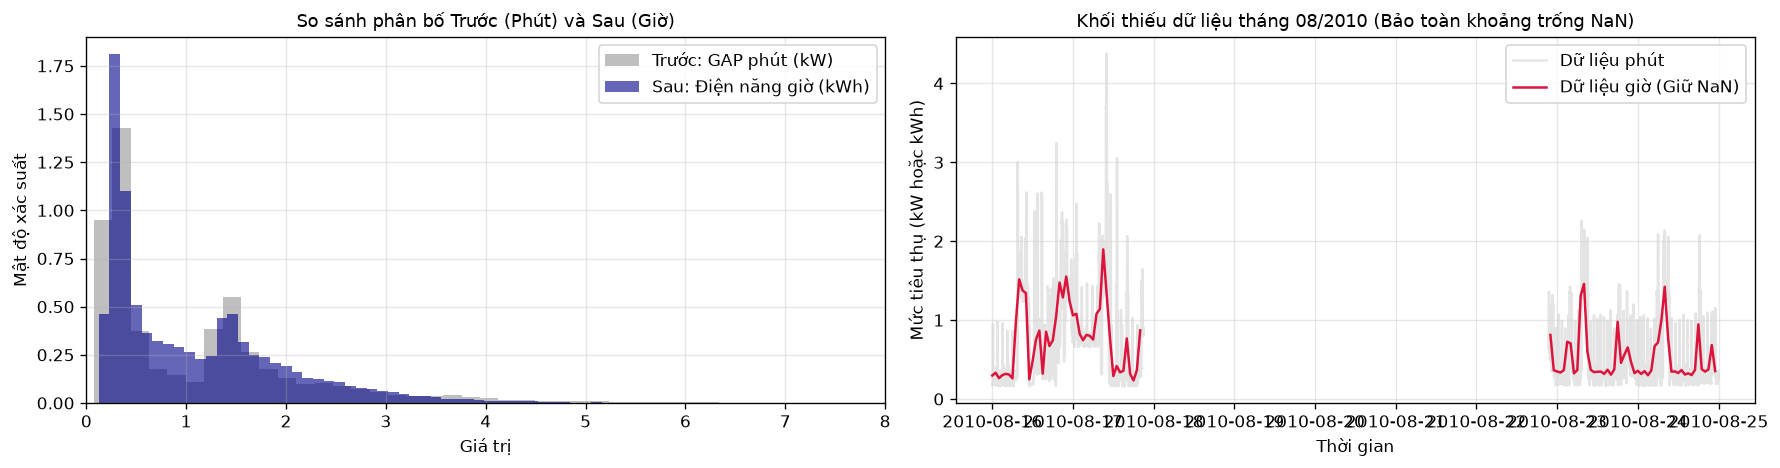

In [17]:
fig, (ax_dist, ax_gap) = plt.subplots(1, 2, figsize=(15, 4))

ax_dist.hist(before_gap.dropna(), bins=60, density=True, alpha=0.5, color="gray", label="Trước: GAP phút (kW)")
ax_dist.hist(after_energy.dropna(), bins=60, density=True, alpha=0.6, color="darkblue", label="Sau: Điện năng giờ (kWh)")
ax_dist.set_xlim(0, 8)
set_labels(ax_dist, "So sánh phân bố Trước (Phút) và Sau (Giờ)", "Giá trị", "Mật độ xác suất")

period = slice("2010-08-16", "2010-08-24") # đoạn chứa khối thiếu dài nhất (120,4 giờ): giữ NaN, không nối suy diễn
ax_gap.plot(before_gap.loc[period], color="lightgray", alpha=0.6, label="Dữ liệu phút")
ax_gap.plot(after_energy.loc[period], color="crimson", lw=1.5, label="Dữ liệu giờ (Giữ NaN)")
set_labels(ax_gap, "Khối thiếu dữ liệu tháng 08/2010 (Bảo toàn khoảng trống NaN)", "Thời gian", "Mức tiêu thụ (kW hoặc kWh)")

for ax in (ax_dist, ax_gap):
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Phân tích quan hệ giữa các đặc trưng và với đầu ra

Để tránh rò rỉ dữ liệu từ tập kiểm thử tương lai, toàn bộ các phân tích tương quan và hàm tự tương quan chỉ được tính toán trên **tập TRAIN (trước ngày 01/01/2010)**.

### 8.1 Ma trận tương quan giữa các biến đo gốc


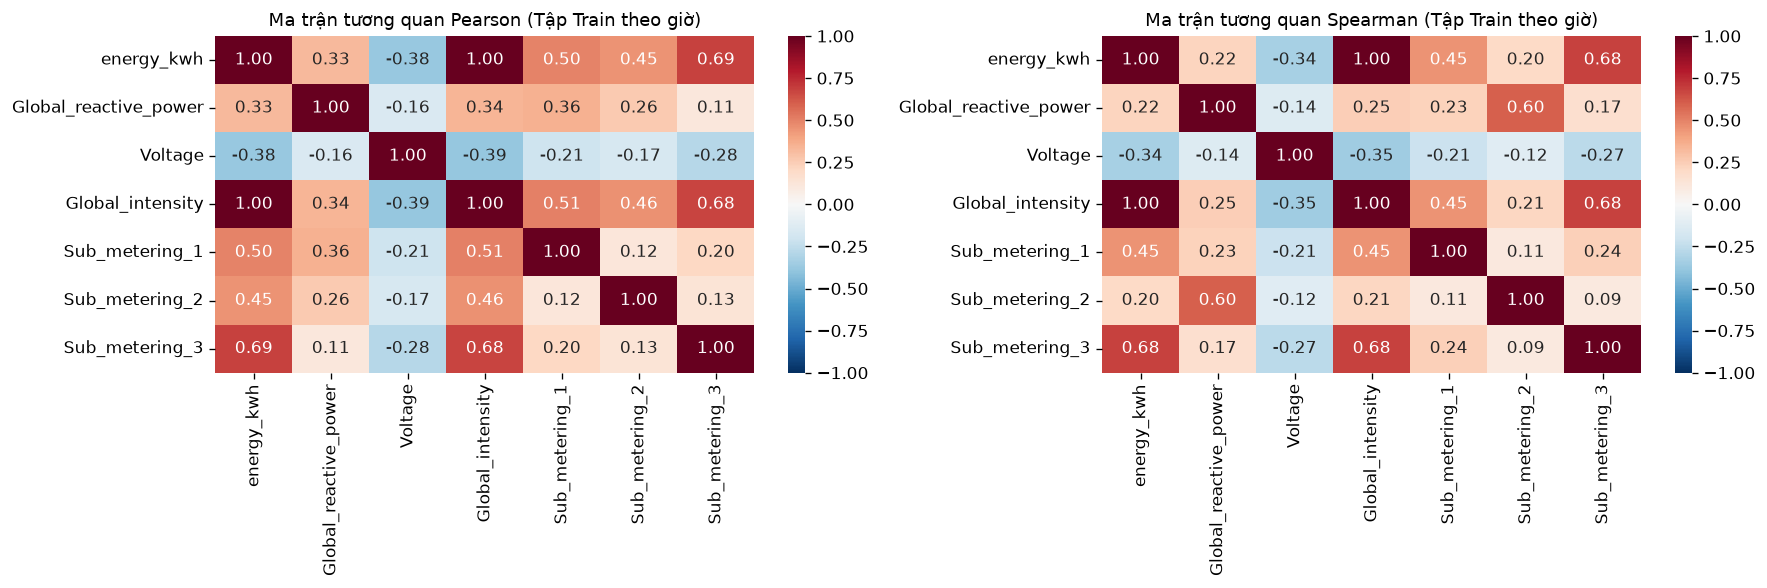

HỆ SỐ TƯƠNG QUAN VỚI NHÃN 'energy_kwh' (TRAIN)


,Pearson,Spearman
energy_kwh,1.000,1.000
Global_intensity,0.999,0.998
Sub_metering_3,0.687,0.684
Sub_metering_1,0.499,0.446
Sub_metering_2,0.450,0.196
Global_reactive_power,0.326,0.219
Voltage,-0.375,-0.336


In [18]:
# Trung bình theo giờ của cả 7 biến (giờ không đủ 54 phút -> NaN), chỉ lấy giai đoạn TRAIN
train_hourly = df_raw.resample("h").mean().where(n_valid_minutes >= THRESH)
train_hourly = train_hourly[train_hourly.index < "2010-01-01"].rename(columns={"Global_active_power": "energy_kwh"})
corr = {"Pearson": train_hourly.corr(), "Spearman": train_hourly.corr(method="spearman")}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (name, matrix) in zip(axes, corr.items()):
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"Ma trận tương quan {name} (Tập Train theo giờ)")
plt.tight_layout()
plt.show()

print("HỆ SỐ TƯƠNG QUAN VỚI NHÃN 'energy_kwh' (TRAIN)")
display(pd.DataFrame({name: m["energy_kwh"] for name, m in corr.items()}).sort_values("Pearson", ascending=False).round(3))

> **Nhận xét ma trận tương quan giữa các biến đo gốc:**
> 1. **Cảnh báo rò rỉ dữ liệu tuyệt đối:** Hệ số tương quan giữa `Global_intensity` và `energy_kwh` đạt **$0,999$** (Pearson; Spearman là $0,998$). Do cường độ dòng điện $I$ đo cùng thời điểm với nhãn, nếu đưa vào làm đặc trưng đầu vào sẽ làm mô hình bị rò rỉ đáp án $\implies$ **Bắt buộc loại bỏ hoàn toàn**.
> 2. **Tương quan giữa các phân nhóm phụ tải với điện năng tổng:**
>    - `Sub_metering_3` (Bình nước nóng & điều hòa) có tương quan mạnh nhất ($r = 0,687$).
>    - `Sub_metering_1` (Bếp) tương quan vừa ($r = 0,499$), `Sub_metering_2` (Giặt/sấy) tương quan $r = 0,450$.
> 3. **Tương quan âm của điện áp lưới (`Voltage`):**
>    - Điện áp có tương quan âm vừa phải với điện năng tiêu thụ ($r = -0,375$). Khi cả hộ hoặc khu dân cư đồng loạt bật tải công suất lớn, hiện tượng sụt áp trên đường dây truyền tải sẽ xảy ra khiến điện áp đo được tại ổ cắm giảm xuống.
> 4. **Công suất phản kháng (`Global_reactive_power`):** Tương quan dương yếu ($r = 0,326$) với điện năng tổng.

In [19]:
H = 1  # tầm dự báo
df_features = pd.DataFrame({f"lag_{k}": energy_hourly.shift(k) for k in (0, 1, 5, 23, 167)}) # đặc trưng trễ (<= t)
target_time = df_features.index + pd.Timedelta(hours=H)
df_features["hour"] = target_time.hour # đặc trưng lịch tính cho thời điểm MỤC TIÊU t + H
df_features["target"] = energy_hourly.shift(-H)

train_ft = df_features[target_time < "2010-01-01"].dropna(subset=["target"])
spearman = train_ft.corr(method="spearman")

print(f"Số lượng mẫu train hợp lệ (h = {H}): {len(train_ft):,}")
print(f"TƯƠNG QUAN HẠNG SPEARMAN VỚI TARGET (TRAIN, h = {H})")
display(spearman["target"].sort_values(ascending=False).round(3))
print("\nMA TRẬN TƯƠNG QUAN GIỮA CÁC ĐẶC TRƯNG ĐẦU VÀO")
display(spearman.drop(index="target", columns="target").round(3))

Số lượng mẫu train hợp lệ (h = 1): 26,523
TƯƠNG QUAN HẠNG SPEARMAN VỚI TARGET (TRAIN, h = 1)


target     1.000
lag_0      0.764
lag_1      0.534
lag_23     0.516
lag_167    0.512
hour       0.347
lag_5      0.026
Name: target, dtype: float64


MA TRẬN TƯƠNG QUAN GIỮA CÁC ĐẶC TRƯNG ĐẦU VÀO


,lag_0,lag_1,lag_5,lag_23,lag_167,hour
lag_0,1.000,0.764,0.087,0.463,0.460,0.363
lag_1,0.764,1.000,0.196,0.347,0.341,0.298
lag_5,0.087,0.196,1.000,0.003,-0.026,-0.057
lag_23,0.463,0.347,0.003,1.000,0.460,0.347
lag_167,0.460,0.341,-0.026,0.460,1.000,0.345
hour,0.363,0.298,-0.057,0.347,0.345,1.000


### 8.2 Hàm tự tương quan (Autocorrelation Function - ACF) trên chuỗi Train
Hàm tự tương quan được tính toán trực tiếp trên chuỗi `energy_hourly` (giữ nguyên vị trí các ô `NaN` trên lưới thời gian để độ trễ $k$ biểu diễn chính xác khoảng cách $k$ giờ).


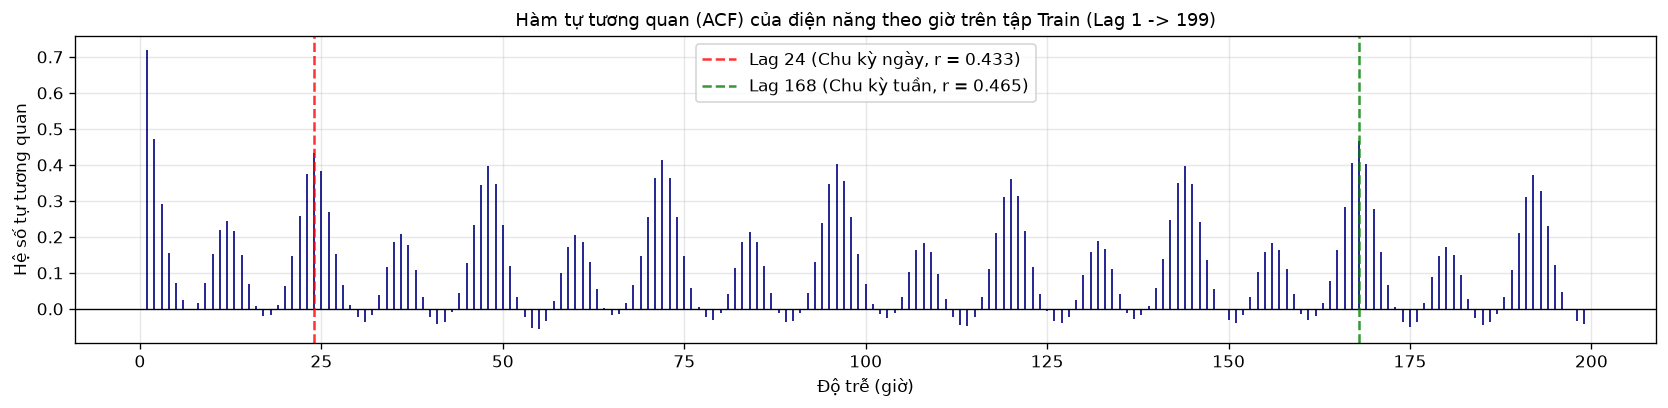

CÁC MỐC TỰ TƯƠNG QUAN QUAN TRỌNG
- Lag 1 (1 giờ trước)           : 0.719
- Lag 6 (6 giờ trước)           : 0.023
- Lag 24 (cùng giờ hôm qua)     : 0.433
- Lag 168 (cùng giờ tuần trước) : 0.465


In [20]:
# Giữ nguyên NaN trên lưới thời gian (không dropna) để độ trễ k đúng bằng k giờ
y_train = energy_hourly[energy_hourly.index < "2010-01-01"]
acf = pd.Series({k: y_train.autocorr(k) for k in range(1, 200)})
lag1, lag6, lag24, lag168 = (acf[k] for k in (1, 6, 24, 168))

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.vlines(acf.index, 0, acf.values, color="navy", lw=1)
ax.axhline(0, color="black", lw=0.8)
ax.axvline(24, color="red", ls="--", alpha=0.8, label=f"Lag 24 (Chu kỳ ngày, r = {lag24:.3f})")
ax.axvline(168, color="green", ls="--", alpha=0.8, label=f"Lag 168 (Chu kỳ tuần, r = {lag168:.3f})")
set_labels(ax, "Hàm tự tương quan (ACF) của điện năng theo giờ trên tập Train (Lag 1 -> 199)", "Độ trễ (giờ)", "Hệ số tự tương quan")
ax.legend()
plt.tight_layout()
plt.show()

print("CÁC MỐC TỰ TƯƠNG QUAN QUAN TRỌNG")
for name, value in (("Lag 1 (1 giờ trước)", lag1), ("Lag 6 (6 giờ trước)", lag6),
                    ("Lag 24 (cùng giờ hôm qua)", lag24), ("Lag 168 (cùng giờ tuần trước)", lag168)):
    print(f"- {name:<30}: {value:.3f}")

> **Bốn nhận xét cốt lõi định hình thiết kế mô hình học máy:**
> 1. **Suy giảm tương quan ngắn hạn và Sự hồi phục ở chu kỳ mùa vụ:**
>    Tự tương quan giảm rất nhanh từ $\text{lag}_1 = 0,719$ xuống gần bằng $0$ ở $\text{lag}_6 = 0,023$ (Spearman với nhãn ở $\text{lag}_5$ chỉ còn $0,026$). Tuy nhiên, hệ số tương quan tăng vọt trở lại tại $\text{lag}_{24} = 0,433$ và $\text{lag}_{168} = 0,465$.
>    $\implies$ **Hành động cho mô hình:** Ở tầm dự báo xa ($h \ge 6$), các lag quá khứ gần không còn tác dụng; mô hình bắt buộc phải dựa vào các đặc trưng chu kỳ mùa vụ như cùng giờ hôm trước ($\text{lag}_{24-h}$) và cùng giờ tuần trước ($\text{lag}_{168-h}$).
> 2. **Quan hệ phi tuyến của đặc trưng lịch (`hour`):**
>    Mức độ tiêu thụ theo giờ trong ngày có quan hệ phi tuyến hình chữ U ngược kết hợp hai đỉnh (thấp ban đêm, cao vào sáng và tối), tương quan hạng Spearman với target đạt $0,347$.
>    $\implies$ **Hành động cho mô hình:** Nếu dùng mô hình tuyến tính (Ridge Regression), bắt buộc phải mã hóa `One-Hot` hoặc biến đổi lượng giác $\sin/\cos$ cho `hour` và `month`. Nếu dùng mô hình cây (Random Forest, LightGBM), cây có thể tự phân nhánh để nắm bắt quan hệ phi tuyến này.
> 3. **Loại bỏ biến rò rỉ dữ liệu `Global_intensity`:**
>    Hệ số tương quan Pearson giữa `Global_intensity` và `energy_kwh` bằng **$0,999$** (gần như trùng khớp tuyệt đối do $P \approx U \times I$).
>    $\implies$ **Hành động cho mô hình:** Cấm tuyệt đối không đưa `Global_intensity` hay `Voltage` đồng thời vào làm đầu vào của mô hình dự báo.
> 4. **Hiện tượng đa cộng tuyến giữa các đặc trưng trễ (Collinearity):**
>    Ma trận tương quan giữa các đặc trưng đầu vào cho thấy tương quan nội bộ đáng kể giữa các biến trễ (ví dụ `lag_0` và `lag_1` tương quan $0,764$; `lag_23` và `lag_167` tương quan $0,460$).
>    $\implies$ **Hành động cho mô hình:** Mô hình tuyến tính bắt buộc phải áp dụng điều chuẩn L2 (Ridge Regularization) để kiểm soát phương sai của trọng số, tránh hiện tượng quá khớp (overfitting).

### 8.3 Tổng hợp theo ngày và Tính mùa vụ ở thang ngày
* **Quy tắc tổng hợp:** Điện năng ngày $E_{\text{ngày}} = \sum_{24\text{ giờ}} E_{\text{giờ}}$ (kWh). Chỉ giữ các ngày đủ **24 giờ hợp lệ** (`min_count=24`); ngày có giờ NaN bị gán `NaN` để không đánh giá thấp điện năng của ngày đó.
* Phân tích chỉ dùng **tập Train** (trước 01/01/2010), giống các mục trước.

CHUỖI ĐIỆN NĂNG THEO NGÀY
Tổng số ngày: 1,442 | Đủ 24 giờ: 1,411 | Bị loại: 31
Train: 1,097 ngày hợp lệ | TB 26.43 | Trung vị 26.07 | ĐLC 10.48 | Min 4.17 | Max 79.56 kWh/ngày | Skew 0.59


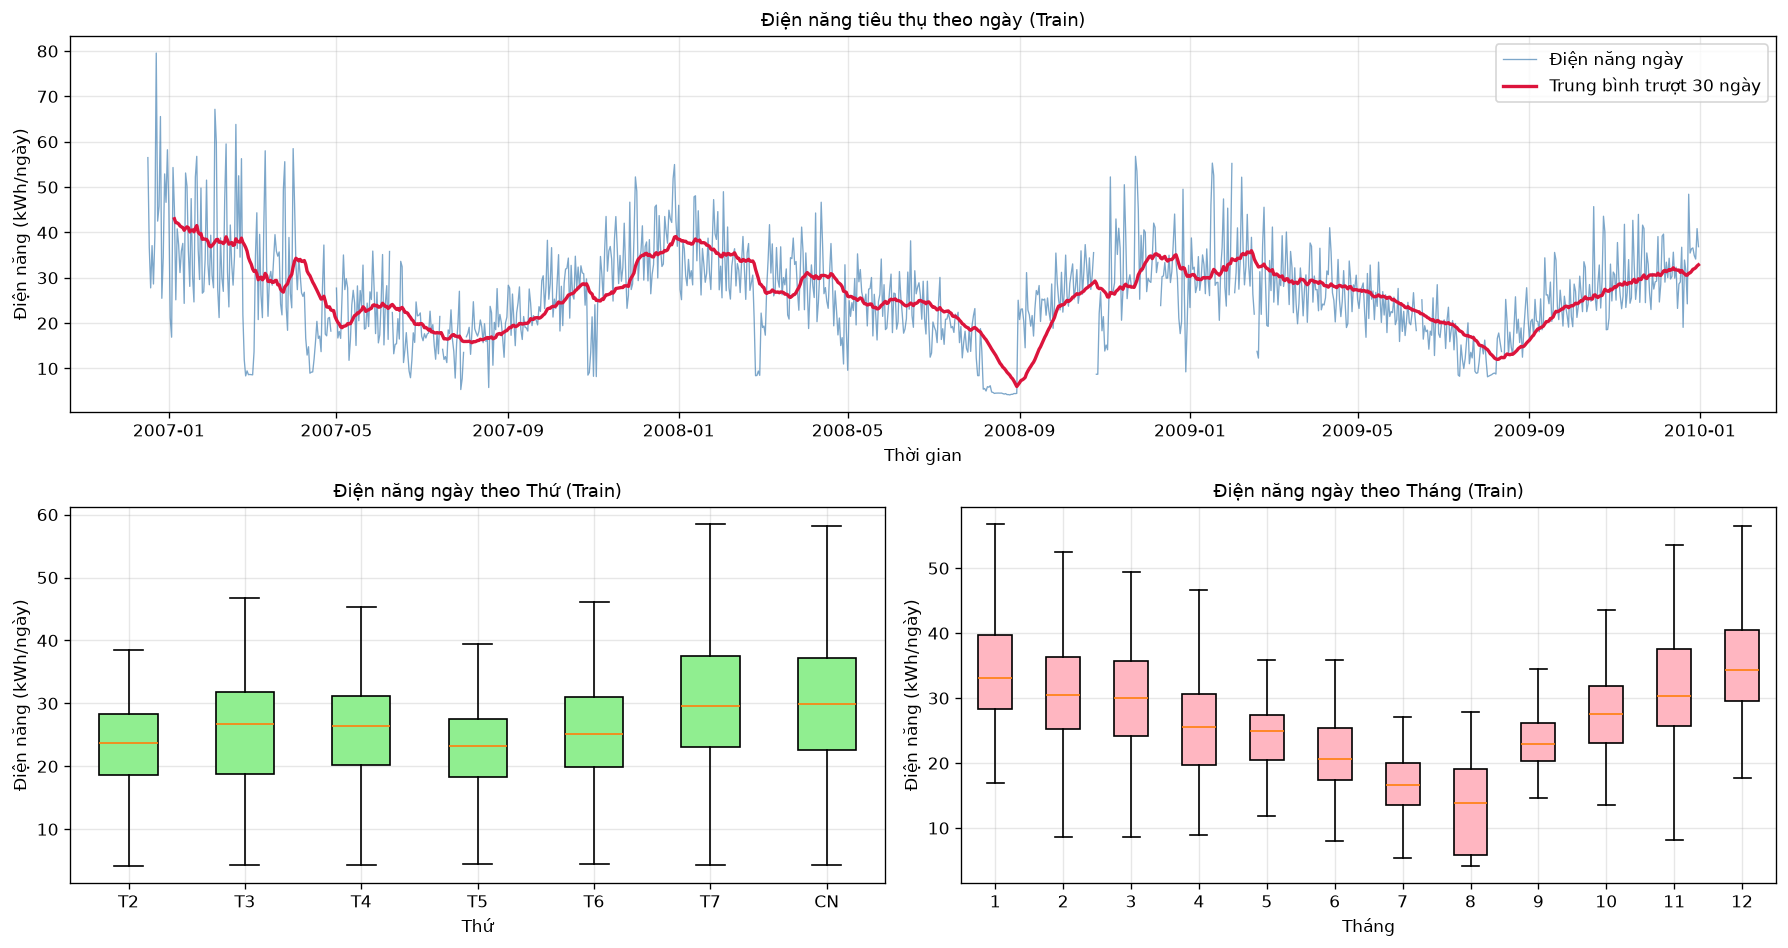

TRUNG VỊ THEO THỨ (kWh/ngày): T2 23.73, T3 26.79, T4 26.40, T5 23.24, T6 25.09, T7 29.52, CN 29.86
Tháng cao nhất: 12 (34.31) | Tháng thấp nhất: 8 (13.79)
TỰ TƯƠNG QUAN CHUỖI NGÀY: lag 1 = 0.607, lag 6 = 0.499, lag 7 = 0.554, lag 182 = -0.271, lag 364 = 0.537


In [21]:
# Điện năng theo ngày = tổng 24 giờ; ngày thiếu giờ nào -> NaN (không cộng thiếu)
energy_daily = energy_hourly.resample("D").sum(min_count=24)
daily_train = energy_daily[energy_daily.index < "2010-01-01"]     # giữ NaN để độ trễ k đúng bằng k ngày
dt = daily_train.dropna()

print("CHUỖI ĐIỆN NĂNG THEO NGÀY")
print(f"Tổng số ngày: {len(energy_daily):,} | Đủ 24 giờ: {energy_daily.notna().sum():,} | Bị loại: {energy_daily.isna().sum():,}")
print(f"Train: {len(dt):,} ngày hợp lệ | TB {dt.mean():.2f} | Trung vị {dt.median():.2f} | ĐLC {dt.std():.2f} | "
      f"Min {dt.min():.2f} | Max {dt.max():.2f} kWh/ngày | Skew {dt.skew():.2f}")

fig = plt.figure(figsize=(15, 8))
ax_ts = fig.add_subplot(2, 1, 1)
ax_dow, ax_month = fig.add_subplot(2, 2, 3), fig.add_subplot(2, 2, 4)

ax_ts.plot(daily_train, color="steelblue", lw=0.8, alpha=0.7, label="Điện năng ngày")
ax_ts.plot(daily_train.rolling(30, min_periods=20).mean(), color="crimson", lw=2, label="Trung bình trượt 30 ngày")
set_labels(ax_ts, "Điện năng tiêu thụ theo ngày (Train)", "Thời gian", "Điện năng (kWh/ngày)")
ax_ts.legend()

for ax, key, ticks, color, title, xlabel in (
        (ax_dow, dt.index.day_of_week, ["T2", "T3", "T4", "T5", "T6", "T7", "CN"], "lightgreen", "Điện năng ngày theo Thứ (Train)", "Thứ"),
        (ax_month, dt.index.month, [str(m) for m in range(1, 13)], "lightpink", "Điện năng ngày theo Tháng (Train)", "Tháng")):
    groups = [g.values for _, g in dt.groupby(key)]
    ax.boxplot(groups, tick_labels=ticks, showfliers=False, patch_artist=True, boxprops={"facecolor": color})
    set_labels(ax, title, xlabel, "Điện năng (kWh/ngày)")
plt.tight_layout()
plt.show()

med_dow, med_month = dt.groupby(dt.index.day_of_week).median(), dt.groupby(dt.index.month).median()
print("TRUNG VỊ THEO THỨ (kWh/ngày):", ", ".join(f"{d} {v:.2f}" for d, v in zip(["T2", "T3", "T4", "T5", "T6", "T7", "CN"], med_dow)))
print(f"Tháng cao nhất: {med_month.idxmax()} ({med_month.max():.2f}) | Tháng thấp nhất: {med_month.idxmin()} ({med_month.min():.2f})")
print("TỰ TƯƠNG QUAN CHUỖI NGÀY:", ", ".join(f"lag {k} = {daily_train.autocorr(k):.3f}" for k in (1, 6, 7, 182, 364)))

> **Nhận xét chuỗi điện năng theo ngày (tập Train):**
> 1. **Ảnh hưởng của dữ liệu thiếu:** trong $1.442$ ngày có $31$ ngày bị loại vì thiếu ít nhất một giờ (gồm cả ngày đầu và ngày cuối không trọn vẹn). Tập Train còn $1.097$ ngày hợp lệ, trung bình $26,43$ kWh/ngày (trung vị $26,07$, độ lệch chuẩn $10,48$). Ở thang ngày, phân bố gần đối xứng hơn nhiều so với thang giờ (skew $0,59$ so với $1,31$), vì các đỉnh trong ngày đã được cộng gộp.
> 2. **Mùa vụ theo năm rất rõ:** đường trung bình trượt 30 ngày dao động theo năm; trung vị tháng 12 ($34,31$ kWh/ngày) gấp khoảng $2,5$ lần tháng 8 ($13,79$). Tự tương quan của chuỗi ngày ở độ trễ 364 ngày là $0,537$, trong khi ở độ trễ 182 ngày (nửa năm, mùa ngược lại) là $-0,271$.
> 3. **Mùa vụ theo tuần:** thứ Bảy ($29,52$) và Chủ nhật ($29,86$) có trung vị cao nhất; thấp nhất là thứ Năm ($23,24$) và thứ Hai ($23,73$). Tự tương quan ở độ trễ 7 ngày ($0,554$) cao hơn độ trễ 6 ngày ($0,499$), xác nhận chu kỳ tuần đã thấy ở ACF theo giờ (độ trễ 168).
> 4. **Hệ quả cho mô hình:** cần đặc trưng tháng (hoặc mùa) và ngày trong tuần/cờ cuối tuần; đặc trưng cửa sổ trượt dài (168 giờ) giúp mô hình nắm được mức nền của tuần hiện tại. Nguyên nhân tháng 8 thấp (giả thuyết: kỳ nghỉ hè) không kiểm chứng được từ dữ liệu.

## 9. Tổng kết và Chuyển giao dữ liệu sang Notebook 02

* **Kết quả đạt được trong Notebook 01:**
  - Hoàn thành đầy đủ từ điển dữ liệu, định hình Schema chuẩn với DatetimeIndex.
  - Định lượng chính xác 9 vấn đề chất lượng dữ liệu, phát hiện 6 khối thiếu dữ liệu dài ngày và bẫy rò rỉ dữ liệu của `Global_intensity`.
  - Thực hiện tổng hợp theo giờ với ngưỡng 54 phút, bảo toàn điện năng và lưu trữ bảng sạch vào `data/processed/hourly.parquet` (34.143 giờ hợp lệ).
  - Phân tích tương quan và tự tương quan, rút ra 4 nguyên tắc thiết kế đặc trưng cho mô hình học máy.
* **Chuyển giao sang `02_chuan_bi_du_lieu.ipynb`:**
  - Bảng dữ liệu `hourly.parquet` được nạp trực tiếp vào Notebook 02 để xây dựng bảng đặc trưng có giám sát, phân chia Train/Test theo thời gian (`TimeSeriesSplit` có `gap = 168`), mã hóa One-Hot và chuẩn hóa StandardScaler bên trong Scikit-learn Pipeline với cam kết fit chỉ trên Train.
